#Research Capstone Notebook

**Task 1 – Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


Purpose:
pandas – Data handling
numpy – Numerical calculations
matplotlib – Visualization
seaborn – Statistical graphs
sklearn – Machine learning and model evaluation

**Task 2 – Load the Dataset**

In [3]:
df = pd.read_csv("/content/student_study_data.csv")

print(df.head())

   Study_Hours  Exam_Score
0            1          35
1            2          40
2            3          50
3            4          55
4            5          60


**Task 3 – Explore the Dataset**

In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Shape: (10, 2)

Column Names:
['Study_Hours', 'Exam_Score']

Data Types:
Study_Hours    int64
Exam_Score     int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Study_Hours  10 non-null     int64
 1   Exam_Score   10 non-null     int64
dtypes: int64(2)
memory usage: 292.0 bytes


**Task 4 – Check Missing Values**

In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Study_Hours    0
Exam_Score     0
dtype: int64


**Task 5 – Statistical Summary**

In [6]:
df.describe()

,Study_Hours,Exam_Score
count,10.00000,10.000000
mean,5.50000,65.500000
std,3.02765,20.876622
min,1.00000,35.000000
25%,3.25000,51.250000
50%,5.50000,65.000000
75%,7.75000,82.500000
max,10.00000,95.000000


**Task 6 – Visualize Study Hours vs Exam Score**

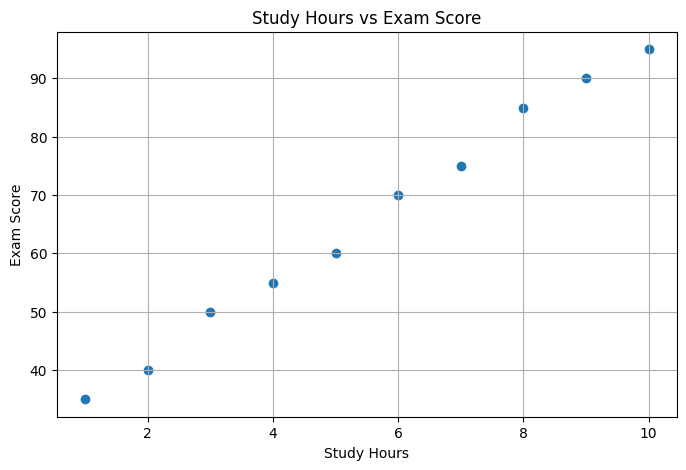

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Study_Hours"], df["Exam_Score"])

plt.title("Study Hours vs Exam Score")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.grid(True)
plt.show()

**Task 7 – Visualize Attendance vs Exam Score**

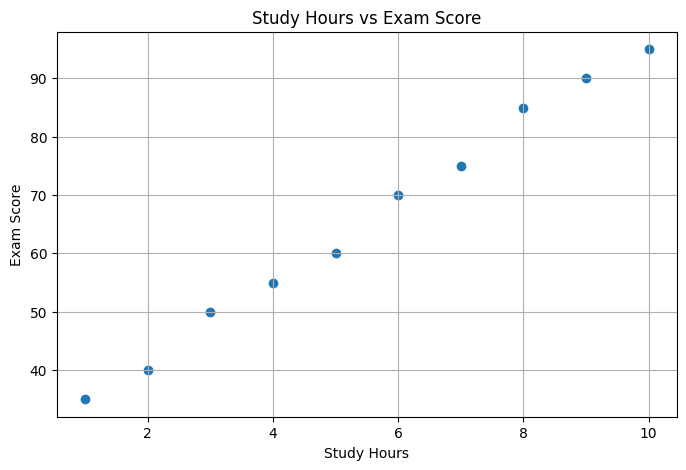

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Study_Hours"], df["Exam_Score"])

plt.title("Study Hours vs Exam Score")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.grid(True)
plt.show()

**Task 8 – Correlation Analysis**

In [12]:
correlation = df.corr(numeric_only=True)

print("Correlation Analysis:")
print(correlation)

Correlation Analysis:
             Study_Hours  Exam_Score
Study_Hours     1.000000    0.997602
Exam_Score      0.997602    1.000000


What does correlation mean?
Near +1 → Positive relationship.
Near -1 → Negative relationship.
Near 0 → Weak linear relationship.

**Task 9 – Correlation Heatmap**

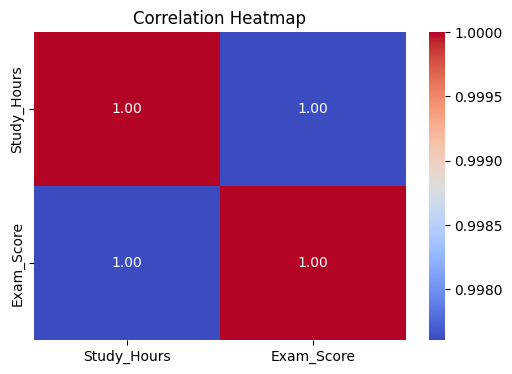

In [13]:
plt.figure(figsize=(6, 4))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

**Task 10 – Prepare Data for Machine Learning**

In [15]:
X = df[["Study_Hours"]]
y = df["Exam_Score"]

print("Input Data:")
print(X.head())

print("\nTarget Data:")
print(y.head())

Input Data:
   Study_Hours
0            1
1            2
2            3
3            4
4            5

Target Data:
0    35
1    40
2    50
3    55
4    60
Name: Exam_Score, dtype: int64


**Task 11 – Split Training and Testing Data**

Now we will divide the dataset into two parts:
80% Training data – To train the model.
20% Testing data – To test the model.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8, 1)
Testing Data: (2, 1)


**Task 12 – Train Linear Regression Model**

In [17]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


**Task 13 – Predict Exam Scores**

In [18]:
y_pred = lr_model.predict(X_test)

print("Predicted Exam Scores:")
print(y_pred)

Predicted Exam Scores:
[89.31034483 41.93965517]


**Task 14 – Evaluate Linear Regression Model**

In [19]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1.3146551724137865
MSE: 2.1189432223543316
RMSE: 1.455659033686918
R2 Score: 0.9966096908442331


Simple explanation:
MAE – Average prediction error.
MSE – Mean squared prediction error.
RMSE – Error measured in the target's units.
R² – How much variation the model explains.

**Task 15 – Visualize Actual vs Predicted Scores**

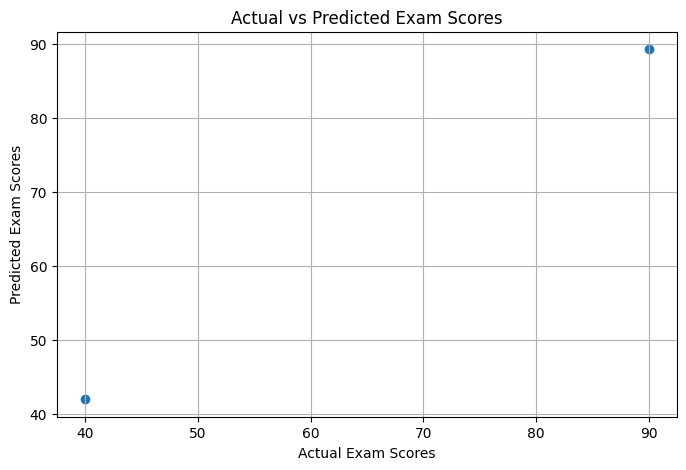

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")
plt.title("Actual vs Predicted Exam Scores")

plt.grid(True)
plt.show()

**Task 16 – Train Random Forest Regression Model**

In [21]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


**Task 17 – Predict Exam Scores Using Random Forest**

In [22]:
rf_pred = rf_model.predict(X_test)

print("Random Forest Predicted Exam Scores:")
print(rf_pred)

Random Forest Predicted Exam Scores:
[86.5  40.45]


**Task 18 – Evaluate Random Forest Model**

In [23]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest MSE:", rf_mse)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2 Score:", rf_r2)

Random Forest MAE: 1.9750000000000014
Random Forest MSE: 6.226250000000001
Random Forest RMSE: 2.4952454789058334
Random Forest R2 Score: 0.990038


**Task 19 – Compare Both Models**

In [24]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

print(comparison)

               Model       MAE      RMSE  R2 Score
0  Linear Regression  1.314655  1.455659  0.996610
1      Random Forest  1.975000  2.495245  0.990038


**Task 20 – Visualize Model Performance**

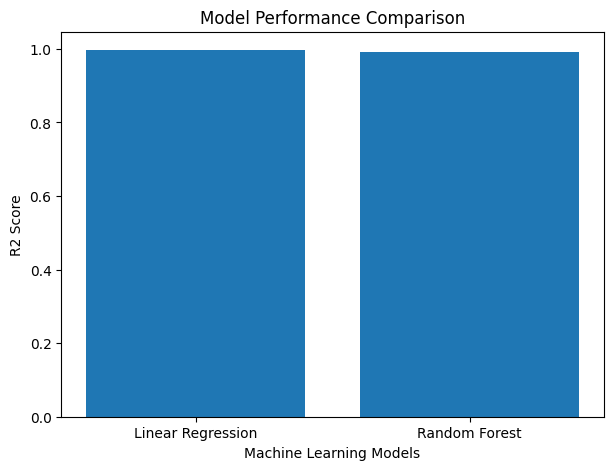

In [25]:
plt.figure(figsize=(7, 5))

plt.bar(comparison["Model"], comparison["R2 Score"])

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")

plt.show()

**Task 21 – Identify the Best Model**

In [26]:
best_model = comparison.loc[comparison["R2 Score"].idxmax()]

print("Best Performing Model:")
print(best_model)

Best Performing Model:
Model       Linear Regression
MAE                  1.314655
RMSE                 1.455659
R2 Score              0.99661
Name: 0, dtype: object


**Task 22 – Random Forest Actual vs Predicted Graph**

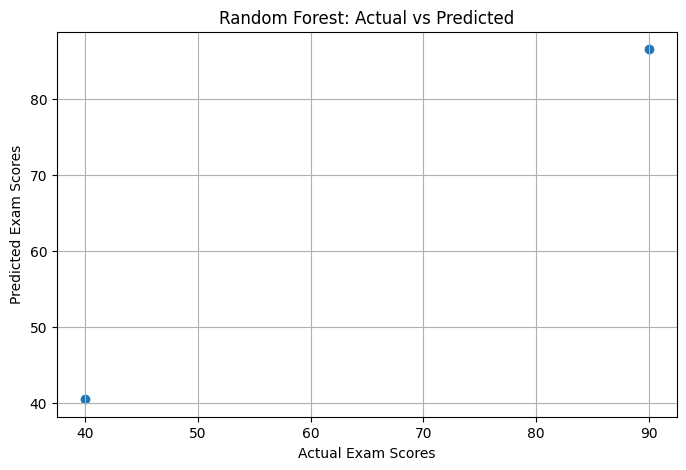

In [27]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_pred)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")
plt.title("Random Forest: Actual vs Predicted")

plt.grid(True)
plt.show()

**Task 23 – Feature Importance**

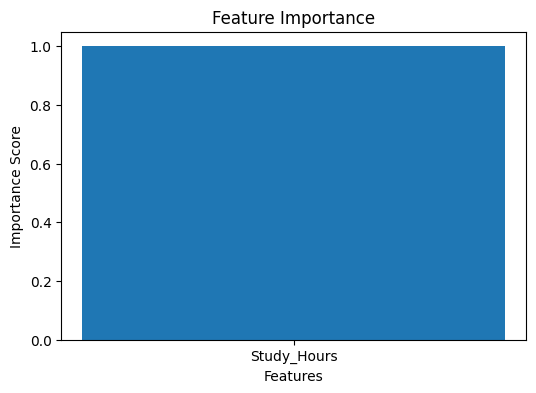

In [28]:
importance = rf_model.feature_importances_

feature_names = X.columns

plt.figure(figsize=(6, 4))
plt.bar(feature_names, importance)

plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance Score")

plt.show()

**Task 24 – Residual Analysis**

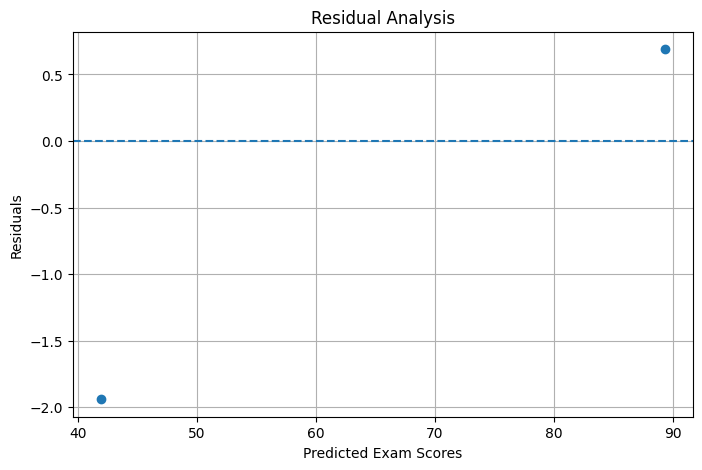

In [29]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, linestyle="--")

plt.title("Residual Analysis")
plt.xlabel("Predicted Exam Scores")
plt.ylabel("Residuals")

plt.grid(True)
plt.show()

**Task 25 – Residual Distribution**

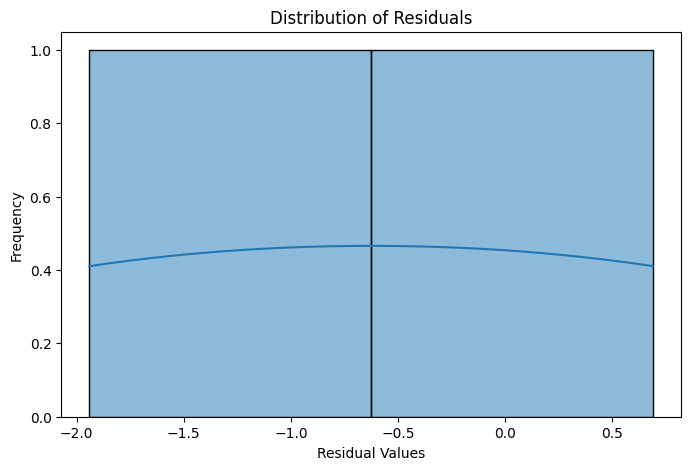

In [30]:
plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title("Distribution of Residuals")
plt.xlabel("Residual Values")
plt.ylabel("Frequency")

plt.show()

**Task 26 –Research Findings**



1. Study hours were analyzed to understand their relationship with exam scores.
2. Correlation analysis was performed to examine the relationship between the variables.
3. Linear Regression and Random Forest models were trained.
4. Both models were evaluated using MAE, MSE, RMSE, and R2 Score.
5. Model performance was compared to identify the better-performing model.
6. Residual analysis was performed to understand prediction errors.

**Task 27 – Business Implications**

Business Implications

1. Educational institutions can use student performance analysis to understand academic outcomes.
2. Study-hour analysis can help students understand their study habits.
3. Predictive models can support early identification of students who may need academic assistance.
4. Teachers can use performance insights to plan additional learning support.
5. Data-driven decisions can help improve educational strategies.

**Task 28 – Research Methodology**



###1. Dataset
The study uses student academic data containing Study_Hours and Exam_score.

### 2. Data Preprocessing
The dataset was loaded using Pandas. Missing values, data types, and statistical summaries were examined.

### 3. Exploratory Data Analysis
Scatter plots and correlation analysis were used to understand the relationship between study hours and exam scores.

### 4. Machine Learning Models
Two regression algorithms were implemented:
- Linear Regression
- Random Forest Regression
###5. Model Evaluation
The models were evaluated using:
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R-squared (R2) Score

**Task 29 – Literature Background**



Student academic performance is influenced by several factors, including study habits, learning activities, and individual effort.

Data analytics and machine learning provide methods to examine student performance and identify patterns in educational data.

Linear Regression is commonly used to study relationships between variables and predict numerical outcomes. Random Forest Regression uses multiple decision trees to make predictions.

This research explores how machine learning techniques can be applied to predict student exam scores using study hours.

**Task 30 – Abstract**



This research focuses on predicting student academic performance using machine learning techniques. The study uses a dataset containing study hours and examination scores.

Exploratory Data Analysis and correlation analysis were performed to understand the relationship between study habits and academic performance.

Two machine learning algorithms, Linear Regression and Random Forest Regression, were implemented. Their performance was evaluated using MAE, MSE, RMSE, and R2 Score.

The objective is to explore how predictive analytics can support educational institutions in understanding student performance and improving learning strategies.

**Task 31 – Research Objectives**



1. To analyze the relationship between student study hours and exam scores.
2. To perform exploratory data analysis on student academic data.
3. To develop predictive models using Linear Regression and Random Forest.
4. To evaluate and compare the performance of both machine learning models.
5. To explore how predictive analytics can support better academic planning.

**Task 32 – Research Limitations**



1. The dataset contains only two variables: Study_Hours and Exam_score.
2. Other factors that may influence academic performance are not included.
3. The prediction results depend on the quality and size of the available dataset.
4. Only two machine learning algorithms were considered.
5. The findings may not represent all students or educational institutions.

**Task 33 – Research Conclusion**



This research explored the relationship between student study hours and examination performance using data analysis and machine learning techniques.

Linear Regression and Random Forest Regression models were developed and evaluated using different performance metrics.

The results provide insights into how study hours can be used to predict examination scores. The study also highlights the potential of predictive analytics in supporting educational decision-making.

Future research can include additional factors such as attendance, learning habits, and previous academic performance to improve prediction accuracy.